In [44]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

from analysis import *

In [45]:
# setup variables
param_1 = 'Match proportion'
param_2 = 'Trim quality'
output_folders = ['../misc_data/S1-OUTPUT_extracted', '../misc_data/S2-OUTPUT_extracted', '../misc_data/S3-OUTPUT_extracted']

In [46]:
# Read the parameter table for each dataset
parameters_by_folder = {
    output_folder: (
        pd.read_csv(f'{output_folder}/parameters.csv')
        .drop_duplicates()
        .set_index('Directory name')
    )
    for output_folder in output_folders
}
next(iter(parameters_by_folder.values())).head()

,Match proportion,Match count,Trim quality,Trim window
Directory name,,,,
S1_MP0.75_MC25_TQ8_TW5-OUTPUT,0.75,25,8,5
S1_MP0.75_MC25_TQ10_TW5-OUTPUT,0.75,25,10,5
S1_MP0.75_MC25_TQ12_TW5-OUTPUT,0.75,25,12,5
S1_MP0.75_MC25_TQ14_TW5-OUTPUT,0.75,25,14,5
S1_MP0.75_MC25_TQ16_TW5-OUTPUT,0.75,25,16,5


In [47]:
output_dirs_by_folder = {
    output_folder: list(parameters_df.index)
    for output_folder, parameters_df in parameters_by_folder.items()
}

In [48]:
# Read and append data for each dataset
allreadcounts_by_folder = {}
for output_folder, output_dirs in output_dirs_by_folder.items():
    allreadcounts_dfs = []
    for output_dir in output_dirs:
        output_path = f'{output_folder}/{output_dir}'
        for fish in sorted(os.listdir(output_path)):
            # Output directories also contain an html report directory. Only
            # load sample directories that contain the expected count file.
            allreadcounts_path = f'{output_path}/{fish}/{fish}.allReadCounts'
            if not os.path.isfile(allreadcounts_path):
                continue
            fish_df = pd.read_csv(allreadcounts_path, sep='\t')
            # Header-only files are valid empty outputs, but including them
            # makes pandas coerce numeric columns to object dtype during concat.
            if fish_df.empty:
                continue
            fish_df['Directory name'] = output_dir
            fish_df['Fish'] = fish
            allreadcounts_dfs.append(fish_df)
    if not allreadcounts_dfs:
        raise ValueError(f'No non-empty .allReadCounts files found in {output_folder}')
    allreadcounts_by_folder[output_folder] = allreadcounts_dfs

next(iter(allreadcounts_by_folder.values()))[0].head()

,event,array,count,proportion,Directory name,Fish
0,NONE_12D+65_NONE_NONE_17D+133_NONE_NONE_NONE_N...,0,4605,0.278231,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
1,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_1D+145_3D+1...,1,3346,0.202163,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
2,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_N...,2,2696,0.162890,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
3,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_5...,3,1830,0.110567,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2
4,1D+38_78D+62_78D+62_78D+62_NONE_8D+173_2D+201_...,4,553,0.033412,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2


In [49]:
results_by_folder = {}
for output_folder, allreadcounts_dfs in allreadcounts_by_folder.items():
    parameters_df = parameters_by_folder[output_folder]
    results_df = pd.concat(allreadcounts_dfs, ignore_index=True)
    for col in parameters_df.columns:
        results_df[col] = results_df['Directory name'].map(parameters_df[col])
    results_by_folder[output_folder] = results_df

next(iter(results_by_folder.values())).head()

,event,array,count,proportion,Directory name,Fish,Match proportion,Match count,Trim quality,Trim window
0,NONE_12D+65_NONE_NONE_17D+133_NONE_NONE_NONE_N...,0,4605,0.278231,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
1,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_1D+145_3D+1...,1,3346,0.202163,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
2,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_N...,2,2696,0.162890,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
3,4D+32&6I+40+CCTATC_6D+59_NONE_NONE_NONE_NONE_5...,3,1830,0.110567,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5
4,1D+38_78D+62_78D+62_78D+62_NONE_8D+173_2D+201_...,4,553,0.033412,S1_MP0.75_MC25_TQ8_TW5-OUTPUT,fish14_s8_rep2,0.75,25,8,5


In [50]:
# Calculate the singleton entry proportion for each parameter combination
info_by_folder = {}
for output_folder, results_df in results_by_folder.items():
    info_df = (
        results_df.groupby([param_1, param_2])
        .agg(total_entries=('count', 'sum'))
        .reset_index()
    )
    count_ones = (
        results_df[results_df['count'] == 1]
        .groupby([param_1, param_2])
        .size()
        .reset_index(name='singleton_entries')
    )
    info_df = info_df.merge(count_ones, on=[param_1, param_2], how='left')
    info_df['singleton_entries'] = info_df['singleton_entries'].fillna(0)
    info_df['singleton_entry_proportion'] = (
        info_df['singleton_entries'] / info_df['total_entries']
    )
    info_by_folder[output_folder] = info_df

next(iter(info_by_folder.values())).head()

,Match proportion,Trim quality,total_entries,singleton_entries,singleton_entry_proportion
0,0.75,8,109191,2712,0.024837
1,0.75,10,109190,2711,0.024828
2,0.75,12,109189,2708,0.024801
3,0.75,14,112136,4392,0.039167
4,0.75,16,105816,2211,0.020895


In [51]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

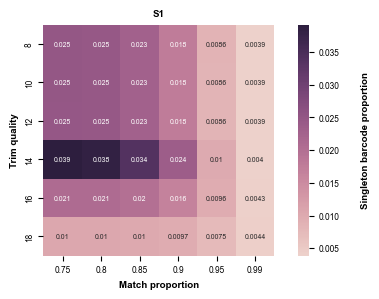

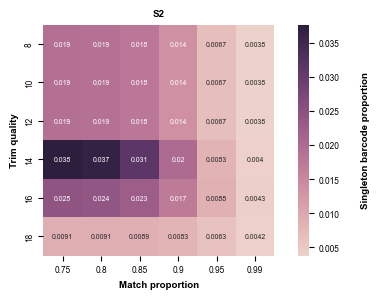

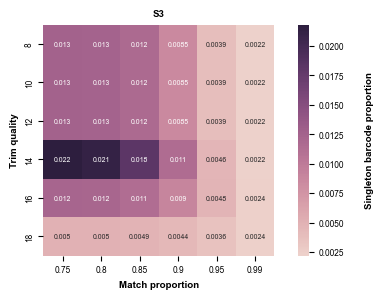

In [52]:
for output_folder, info_df in info_by_folder.items():
    dataset_name = os.path.basename(os.path.normpath(output_folder))
    dataset_name = dataset_name.removesuffix('-OUTPUT_extracted')

    fig, ax = plt.subplots(figsize=(6, 3))
    pivot_data = info_df.pivot(
        index=param_2,
        columns=param_1,
        values='singleton_entry_proportion',
    )
    sb.heatmap(
        pivot_data,
        annot=True,
        square=True,
        cmap=sb.cubehelix_palette(as_cmap=True),
        ax=ax,
        annot_kws={'size': 5},
    )

    ax.set_title(dataset_name, fontweight='bold')
    ax.set_xlabel('Match proportion', fontweight='bold')
    ax.set_ylabel('Trim quality', fontweight='bold')

    cbar = ax.collections[0].colorbar
    cbar.set_label(
        'Singleton barcode proportion',
        labelpad=15,
        fontweight='bold',
    )

    output_stem = f'images/singleton_proportion_{dataset_name}'
    fig.savefig(f'{output_stem}.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'{output_stem}.svg', bbox_inches='tight')
    plt.show()